In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
sarcasm_df = pd.read_json(
    '/content/Sarcasm_Headlines_Dataset.json',
    lines=True
)

display(sarcasm_df.head())

,article_link,headline,is_sarcastic
0,https://www.huffingtonpost.com/entry/versace-b...,former versace store clerk sues over secret 'b...,0
1,https://www.huffingtonpost.com/entry/roseanne-...,the 'roseanne' revival catches up to our thorn...,0
2,https://local.theonion.com/mom-starting-to-fea...,mom starting to fear son's web series closest ...,1
3,https://politics.theonion.com/boehner-just-wan...,"boehner just wants wife to listen, not come up...",1
4,https://www.huffingtonpost.com/entry/jk-rowlin...,j.k. rowling wishes snape happy birthday in th...,0


In [3]:
print("Dataset Shape:", sarcasm_df.shape)

Dataset Shape: (26709, 3)


In [4]:
display(sarcasm_df.head())

,article_link,headline,is_sarcastic
0,https://www.huffingtonpost.com/entry/versace-b...,former versace store clerk sues over secret 'b...,0
1,https://www.huffingtonpost.com/entry/roseanne-...,the 'roseanne' revival catches up to our thorn...,0
2,https://local.theonion.com/mom-starting-to-fea...,mom starting to fear son's web series closest ...,1
3,https://politics.theonion.com/boehner-just-wan...,"boehner just wants wife to listen, not come up...",1
4,https://www.huffingtonpost.com/entry/jk-rowlin...,j.k. rowling wishes snape happy birthday in th...,0


In [5]:
print("Column Names:")
print(sarcasm_df.columns.tolist())

Column Names:
['article_link', 'headline', 'is_sarcastic']


In [6]:
sarcasm_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26709 entries, 0 to 26708
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   article_link  26709 non-null  object
 1   headline      26709 non-null  object
 2   is_sarcastic  26709 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 626.1+ KB


In [7]:
display(sarcasm_df.describe(include='all'))

,article_link,headline,is_sarcastic
count,26709,26709,26709.000000
unique,26708,26602,NaN
top,https://www.huffingtonpost.comhttp://nymag.com...,the 20 funniest tweets from women this week,NaN
freq,2,10,NaN
mean,NaN,NaN,0.438953
std,NaN,NaN,0.496269
min,NaN,NaN,0.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,0.000000
75%,NaN,NaN,1.000000


In [8]:
print("Missing Values:")
print(sarcasm_df.isnull().sum())

Missing Values:
article_link    0
headline        0
is_sarcastic    0
dtype: int64


In [9]:
print("Duplicate Rows:", sarcasm_df.duplicated().sum())

Duplicate Rows: 1


In [10]:
sarcasm_df = sarcasm_df.dropna(
    subset=['headline', 'is_sarcastic']
).copy()

sarcasm_df['headline'] = sarcasm_df['headline'].astype(str)

sarcasm_df = sarcasm_df.drop_duplicates().reset_index(drop=True)

print("Shape After Cleaning:", sarcasm_df.shape)
print("Remaining Missing Values:")
print(sarcasm_df[['headline', 'is_sarcastic']].isnull().sum())

print("Remaining Duplicate Rows:", sarcasm_df.duplicated().sum())

Shape After Cleaning: (26708, 3)
Remaining Missing Values:
headline        0
is_sarcastic    0
dtype: int64
Remaining Duplicate Rows: 0


In [11]:
print(sarcasm_df['is_sarcastic'].value_counts())

is_sarcastic
0    14984
1    11724
Name: count, dtype: int64


In [12]:
class_percentages = (
    sarcasm_df['is_sarcastic']
    .value_counts(normalize=True)
    .mul(100)
)

print("Class Percentages:")
print(class_percentages)

Class Percentages:
is_sarcastic
0    56.10304
1    43.89696
Name: proportion, dtype: float64


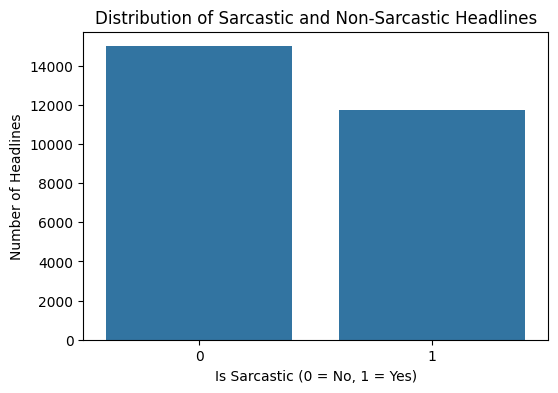

In [13]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=sarcasm_df,
    x='is_sarcastic'
)

plt.title('Distribution of Sarcastic and Non-Sarcastic Headlines')
plt.xlabel('Is Sarcastic (0 = No, 1 = Yes)')
plt.ylabel('Number of Headlines')
plt.show()

In [14]:
sarcasm_df['headline_length'] = sarcasm_df['headline'].str.len()

In [15]:
sarcasm_df['word_count'] = (
    sarcasm_df['headline'].str.split().str.len()
)

In [16]:
sarcasm_df['average_word_length'] = sarcasm_df['headline'].apply(
    lambda text: np.mean([len(word) for word in text.split()])
    if text.split() else 0
)

In [17]:
import string

sarcasm_df['punctuation_count'] = sarcasm_df['headline'].apply(
    lambda text: sum(char in string.punctuation for char in text)
)

In [18]:
display(
    sarcasm_df[
        [
            'headline',
            'is_sarcastic',
            'headline_length',
            'word_count',
            'average_word_length',
            'punctuation_count'
        ]
    ].head()
)

,headline,is_sarcastic,headline_length,word_count,average_word_length,punctuation_count
0,former versace store clerk sues over secret 'b...,0,78,12,5.583333,2
1,the 'roseanne' revival catches up to our thorn...,0,84,14,5.071429,3
2,mom starting to fear son's web series closest ...,1,79,14,4.714286,1
3,"boehner just wants wife to listen, not come up...",1,84,13,5.538462,2
4,j.k. rowling wishes snape happy birthday in th...,0,64,11,4.909091,2


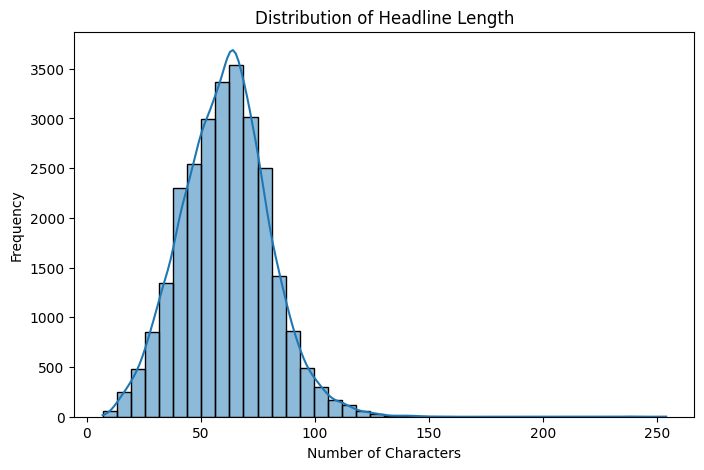

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=sarcasm_df,
    x='headline_length',
    bins=40,
    kde=True
)

plt.title('Distribution of Headline Length')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')
plt.show()

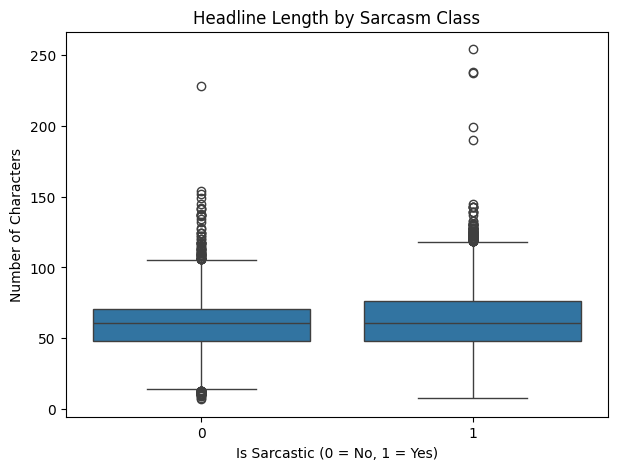

In [20]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=sarcasm_df,
    x='is_sarcastic',
    y='headline_length'
)

plt.title('Headline Length by Sarcasm Class')
plt.xlabel('Is Sarcastic (0 = No, 1 = Yes)')
plt.ylabel('Number of Characters')
plt.show()

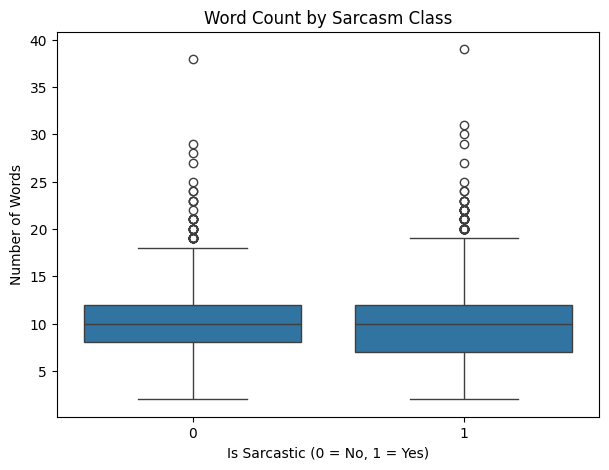

In [21]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=sarcasm_df,
    x='is_sarcastic',
    y='word_count'
)

plt.title('Word Count by Sarcasm Class')
plt.xlabel('Is Sarcastic (0 = No, 1 = Yes)')
plt.ylabel('Number of Words')
plt.show()

In [22]:
length_summary = sarcasm_df.groupby('is_sarcastic')[
    ['headline_length', 'word_count', 'average_word_length',
     'punctuation_count']
].mean()

display(length_summary)

,headline_length,word_count,average_word_length,punctuation_count
is_sarcastic,,,,
0,59.560798,9.816004,5.247899,1.294247
1,62.638605,9.884425,5.559977,0.912317


In [23]:
Q1 = sarcasm_df['headline_length'].quantile(0.25)
Q3 = sarcasm_df['headline_length'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

outliers = sarcasm_df[
    (sarcasm_df['headline_length'] < lower_bound) |
    (sarcasm_df['headline_length'] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Potential Outliers:", len(outliers))

display(
    outliers[
        ['headline', 'is_sarcastic', 'headline_length']
    ].head(10)
)

Lower Bound: 10.5
Upper Bound: 110.5
Number of Potential Outliers: 271


,headline,is_sarcastic,headline_length
21,trump assures nation that decision for syrian ...,1,111
91,'i must make sure you have the skills to pleas...,1,113
113,'is it too late to audition?' asks perfect act...,1,118
215,mark zuckerberg cited for contempt of congress...,1,123
256,melania trump hangs decayed badger carcass ove...,1,118
306,'new york times' moves all content you won't g...,1,128
381,hillary clinton opens new presidential library...,1,113
446,google employees disappointed 15th anniversary...,1,116
531,how to lose to the islamic state: obama admini...,0,117
594,paul ryan confident american people will warm ...,1,113


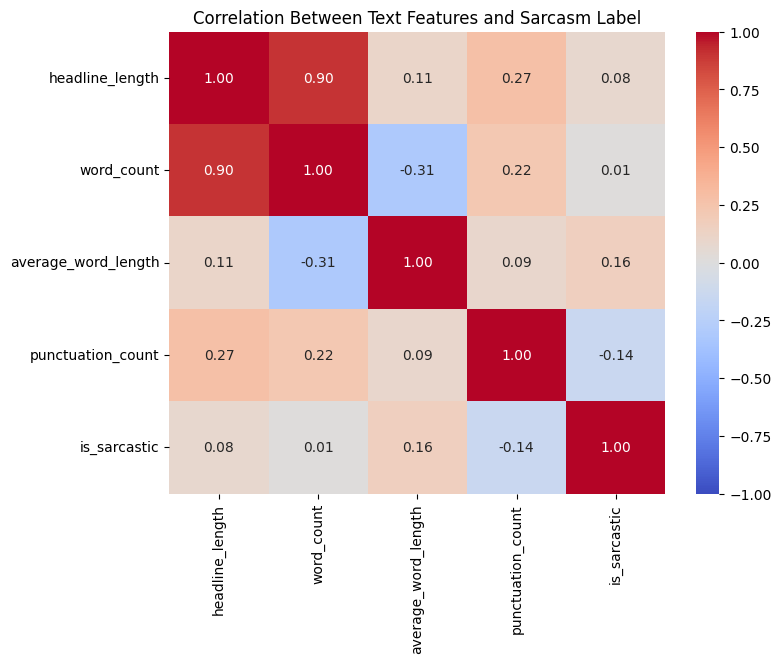

In [24]:
numeric_features = [
    'headline_length',
    'word_count',
    'average_word_length',
    'punctuation_count',
    'is_sarcastic'
]

correlation_matrix = sarcasm_df[numeric_features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Text Features and Sarcasm Label')
plt.show()

In [25]:
print("Total Headlines:", len(sarcasm_df))

print("\nClass Distribution:")
print(sarcasm_df['is_sarcastic'].value_counts())

print("\nClass Percentages:")
print(
    (sarcasm_df['is_sarcastic'].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nAverage Text Features by Class:")
display(
    sarcasm_df.groupby('is_sarcastic')[
        [
            'headline_length',
            'word_count',
            'average_word_length',
            'punctuation_count'
        ]
    ].mean().round(2)
)

print("\nPotential Headline Length Outliers:", len(outliers))

Total Headlines: 26708

Class Distribution:
is_sarcastic
0    14984
1    11724
Name: count, dtype: int64

Class Percentages:
is_sarcastic
0    56.1
1    43.9
Name: proportion, dtype: float64

Average Text Features by Class:


,headline_length,word_count,average_word_length,punctuation_count
is_sarcastic,,,,
0,59.56,9.82,5.25,1.29
1,62.64,9.88,5.56,0.91



Potential Headline Length Outliers: 271


In [26]:
X = sarcasm_df['headline'].values

y = sarcasm_df['is_sarcastic'].astype(int).values

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (26708,)
Target Shape: (26708,)


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 21366
Testing Samples: 5342


In [28]:
max_words = 5000

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token='<OOV>'
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)

X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Original Headline:")
print(X_train[0])

print("\nTokenized Headline:")
print(X_train_seq[0])

Original Headline:
philippine president duterte declares martial law after isis-linked attack

Tokenized Headline:
[4463, 120, 1, 1706, 3994, 273, 21, 558, 1798, 306]


In [29]:
max_len = 50

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

print("Padded Training Shape:", X_train_pad.shape)
print("Padded Testing Shape:", X_test_pad.shape)

print("\nExample Padded Sequence:")
print(X_train_pad[0])

Padded Training Shape: (21366, 50)
Padded Testing Shape: (5342, 50)

Example Padded Sequence:
[4463  120    1 1706 3994  273   21  558 1798  306    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


In [30]:
print("Maximum Token ID:", X_train_pad.max())
print("Minimum Token ID:", X_train_pad.min())

assert X_train_pad.shape[1] == 50
assert X_test_pad.shape[1] == 50

assert X_train_pad.max() < max_words
assert X_test_pad.max() < max_words

Maximum Token ID: 4999
Minimum Token ID: 0


In [31]:
model = Sequential([
    Embedding(5000, 32),
    LSTM(2),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [32]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/5
134/134 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.5607 - loss: 0.6865 - val_accuracy: 0.5547 - val_loss: 0.6874
Epoch 2/5
134/134 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.5626 - loss: 0.6853 - val_accuracy: 0.5547 - val_loss: 0.6872
Epoch 3/5
134/134 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5626 - loss: 0.6854 - val_accuracy: 0.5547 - val_loss: 0.6873
Epoch 4/5
134/134 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.5626 - loss: 0.6854 - val_accuracy: 0.5547 - val_loss: 0.6871
Epoch 5/5
134/134 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.5626 - loss: 0.6854 - val_accuracy: 0.5547 - val_loss: 0.6872


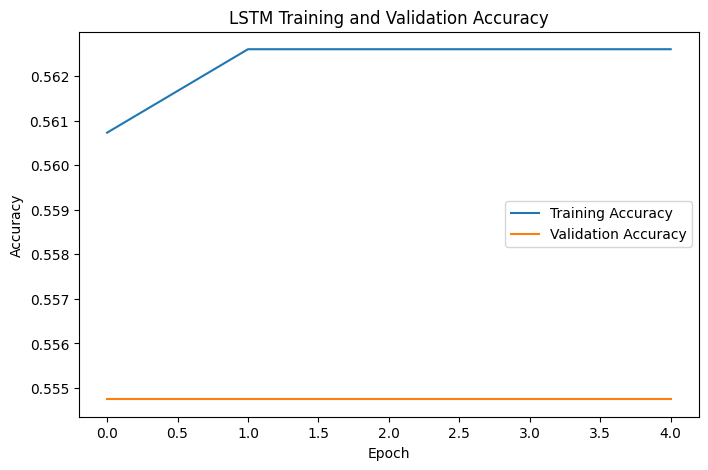

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('LSTM Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [34]:
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.6857
Test Accuracy: 0.5610
Test Accuracy: 56.10%


In [35]:
y_prob = model.predict(X_test_pad, verbose=0)

y_pred = (y_prob >= 0.5).astype(int).ravel()

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Not Sarcastic', 'Sarcastic'],
        zero_division=0
    )
)

               precision    recall  f1-score   support

Not Sarcastic       0.56      1.00      0.72      2997
    Sarcastic       0.00      0.00      0.00      2345

     accuracy                           0.56      5342
    macro avg       0.28      0.50      0.36      5342
 weighted avg       0.31      0.56      0.40      5342



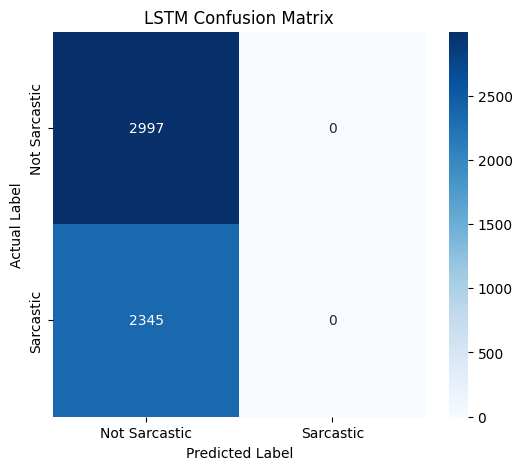

In [36]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Sarcastic', 'Sarcastic'],
    yticklabels=['Not Sarcastic', 'Sarcastic']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('LSTM Confusion Matrix')
plt.show()

The forget gate allows an LSTM to learn which information from its previous cell state should be retained or discarded as it processes a sequence. Unlike a plain RNN, an LSTM uses a gated cell-state pathway that helps preserve useful information over longer sequences and reduces the vanishing-gradient problem, although it does not eliminate it completely.

In this assignment, we performed exploratory data analysis on a news headline dataset and examined the distribution of sarcasm labels, headline lengths, word counts, and potential outliers. We then converted the headlines into token sequences, padded them to a fixed length of 50, and built an LSTM model using an embedding layer, two LSTM units, and a sigmoid output layer. Finally, we trained the model for five epochs and evaluated its performance on a held-out test set using accuracy and classification metrics.